# Experiment_01: topology information (betti numbers)

This notebook is for providing topology information of 2d binary image. The goal is to observe how topology information measure of diffenrent data changes

,name,dice,bce,beta_0,beta_1
0,perfect,1.000000,1.000000e-08,1,0
1,boundary,0.904098,9.893920e-01,1,0
2,hole,0.952936,5.081877e-01,1,1
3,split,0.967132,3.597789e-01,2,0
4,extra_component,0.977449,2.608397e-01,2,0


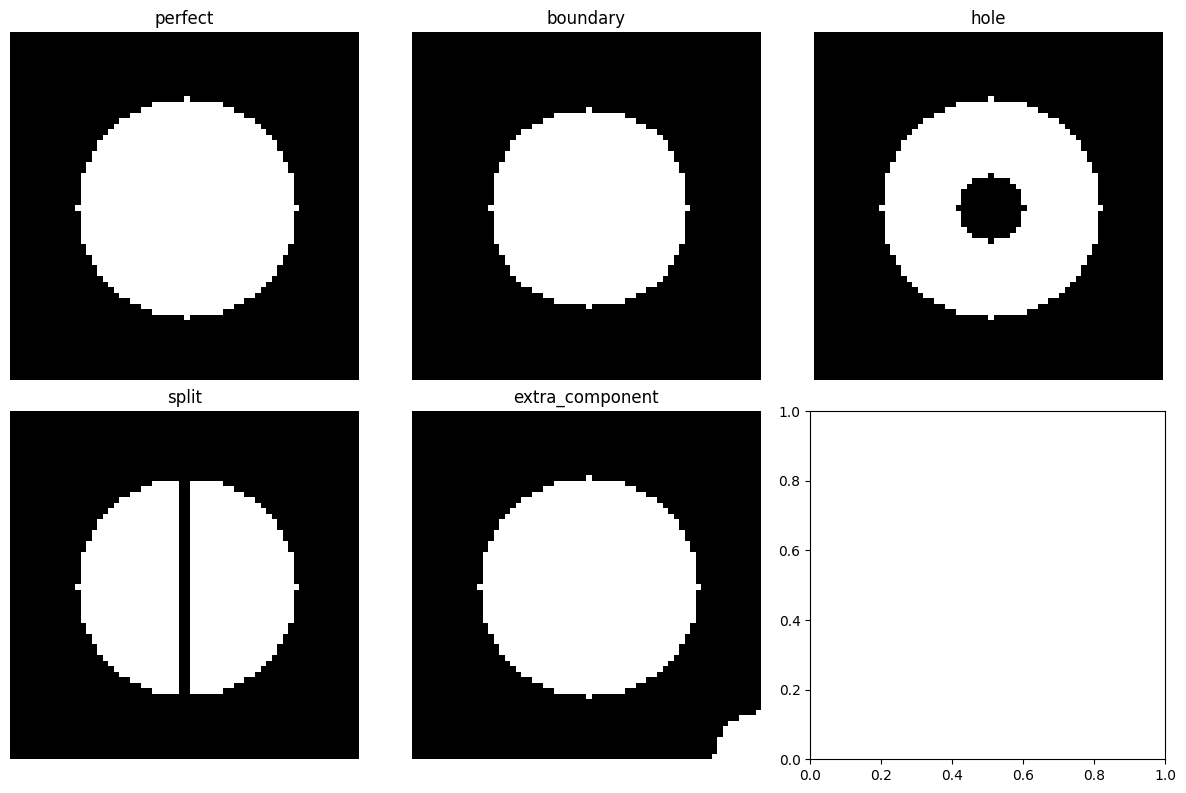

In [6]:
import sys
sys.path.append("/home/yejuny2/Desktop/code/PCE/topological_segmentation/src")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from topological_segmentation.data.synthetic_2d import make_disk
from topological_segmentation.data.perturbations import add_hole, erode_boundary, split_object, add_component
from topological_segmentation.losses.segmentation import dice_score, binary_cross_entropy
from topological_segmentation.topology.betti import compute_betti_numbers

gt = make_disk(size=64, radius=20)

preds = {
    "perfect": gt,
    "boundary": erode_boundary(gt, amount=2),
    "hole": add_hole(gt, radius=6),
    "split": split_object(gt, width=2),
    "extra_component": add_component(gt, radius=8, center=(20, 20)),
}

rows = []
for name, pred in preds.items():
    beta_0, beta_1 = compute_betti_numbers(pred)
    rows.append({
        "name": name,
        "dice": float(dice_score(pred, gt)),
        "bce": float(binary_cross_entropy(pred.astype(float), gt.astype(float))),
        "beta_0": beta_0,
        "beta_1": beta_1,
    })

df = pd.DataFrame(rows)
display(df)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (name, mask) in zip(axes.flat, preds.items()):
    ax.imshow(mask, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()